In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
DATA_PATH = os.path.join("Dataset", "crop_yield.csv")
df = pd.read_csv(DATA_PATH)
df.shape

(19689, 10)

In [3]:
df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  str    
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  str    
 3   State            19689 non-null  str    
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
dtypes: float64(5), int64(2), str(3)
memory usage: 2.1 MB


In [5]:
for col in ["Crop", "Season", "State"]:
    df[col] = df[col].astype(str).str.strip()

df.isnull().sum()

Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

In [6]:
df = df.dropna()
df = df.drop_duplicates()
df = df[(df["Area"] > 0) & (df["Production"] >= 0) & (df["Yield"] > 0)]
df.shape

(19577, 10)

In [7]:
df["Fertilizer_per_Area"] = df["Fertilizer"] / df["Area"]
df["Pesticide_per_Area"] = df["Pesticide"] / df["Area"]
df.describe()

,Crop_Year,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,Fertilizer_per_Area,Pesticide_per_Area
count,19577.000000,1.957700e+04,1.957700e+04,19577.000000,1.957700e+04,1.957700e+04,19577.000000,19577.000000,19577.000000
mean,2009.117945,1.809265e+05,1.652997e+07,1438.450010,2.423721e+07,4.911903e+04,80.411426,137.118281,0.274259
std,6.499877,7.348001e+05,2.638053e+08,816.525914,9.520033e+07,2.138658e+05,880.794251,26.200615,0.073330
min,1997.000000,5.000000e-01,0.000000e+00,301.300000,5.417000e+01,9.000000e-02,0.003571,94.670000,0.090000
25%,2004.000000,1.439000e+03,1.448000e+03,940.700000,1.935634e+05,3.696300e+02,0.604348,108.340000,0.220000
50%,2010.000000,9.501000e+03,1.408200e+04,1247.600000,1.258710e+06,2.473450e+03,1.037273,144.490000,0.270000
75%,2015.000000,7.599300e+04,1.244600e+05,1643.700000,1.013409e+07,2.021619e+04,2.410000,157.910000,0.330000
max,2020.000000,5.080810e+07,6.326000e+09,6552.700000,4.835407e+09,1.575051e+07,21105.000000,193.610000,0.380000


In [8]:
def remove_outliers_iqr(data, cols, factor=3.0):
    out = data.copy()
    for col in cols:
        q1 = out[col].quantile(0.25)
        q3 = out[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - factor * iqr
        upper = q3 + factor * iqr
        out = out[(out[col] >= lower) & (out[col] <= upper)]
    return out

numeric_cols = ["Area", "Production", "Yield", "Annual_Rainfall", "Fertilizer_per_Area", "Pesticide_per_Area"]
df = remove_outliers_iqr(df, numeric_cols, factor=3.0)
df.shape

(13508, 12)

In [9]:
df["Crop"].value_counts().head(15)

Crop
Moong(Green Gram)      682
Sesamum                643
Urad                   639
Maize                  561
Groundnut              551
Rice                   469
Ragi                   467
Small millets          463
Sunflower              412
Rapeseed &Mustard      401
Other Kharif pulses    370
Arhar/Tur              369
Horse-gram             365
Bajra                  350
Gram                   348
Name: count, dtype: int64

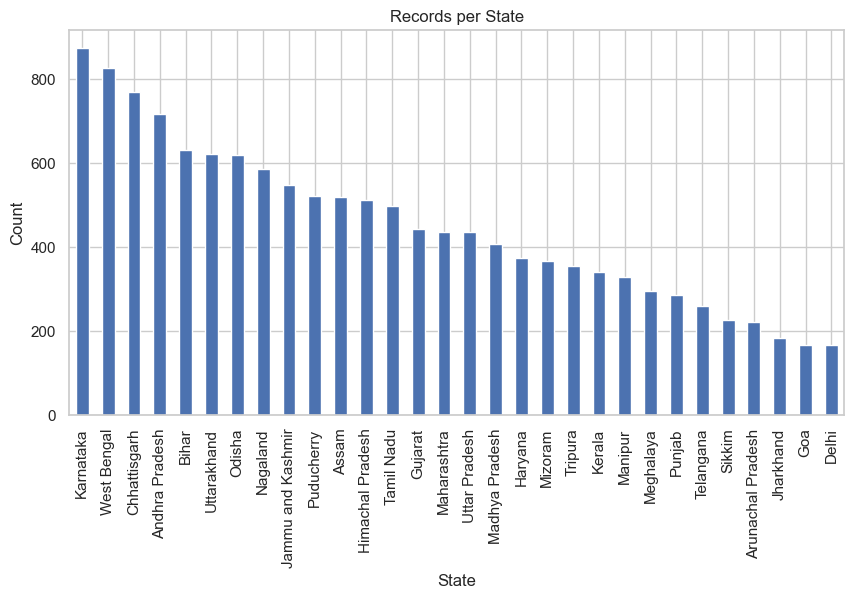

In [10]:
plt.figure(figsize=(10, 5))
df["State"].value_counts().plot(kind="bar")
plt.title("Records per State")
plt.ylabel("Count")
plt.show()

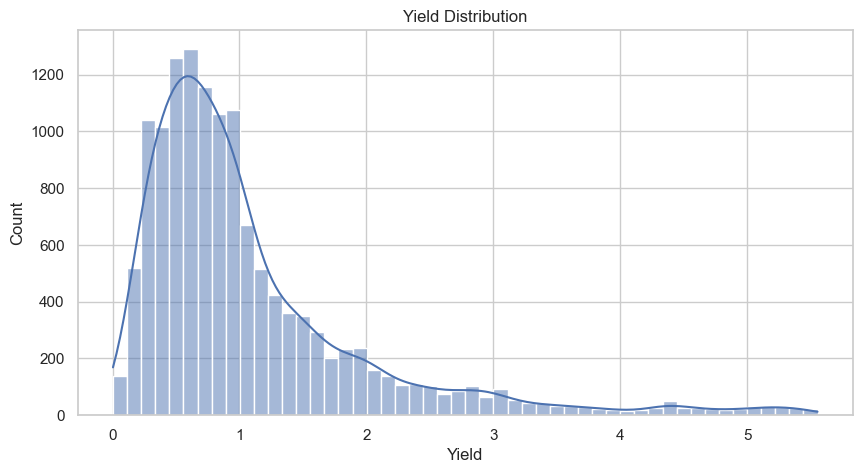

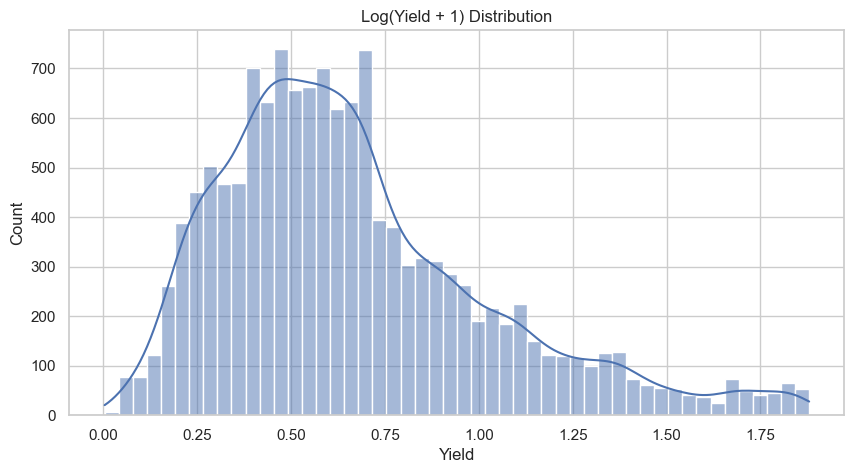

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Yield"], bins=50, kde=True)
plt.title("Yield Distribution")
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df["Yield"]), bins=50, kde=True)
plt.title("Log(Yield + 1) Distribution")
plt.show()

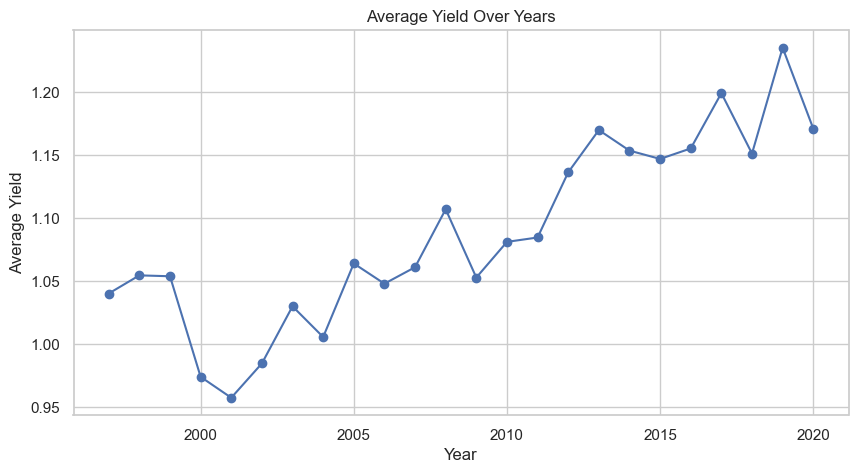

In [12]:
yearly_yield = df.groupby("Crop_Year")["Yield"].mean().reset_index()
plt.figure(figsize=(10, 5))
plt.plot(yearly_yield["Crop_Year"], yearly_yield["Yield"], marker="o")
plt.title("Average Yield Over Years")
plt.xlabel("Year")
plt.ylabel("Average Yield")
plt.show()

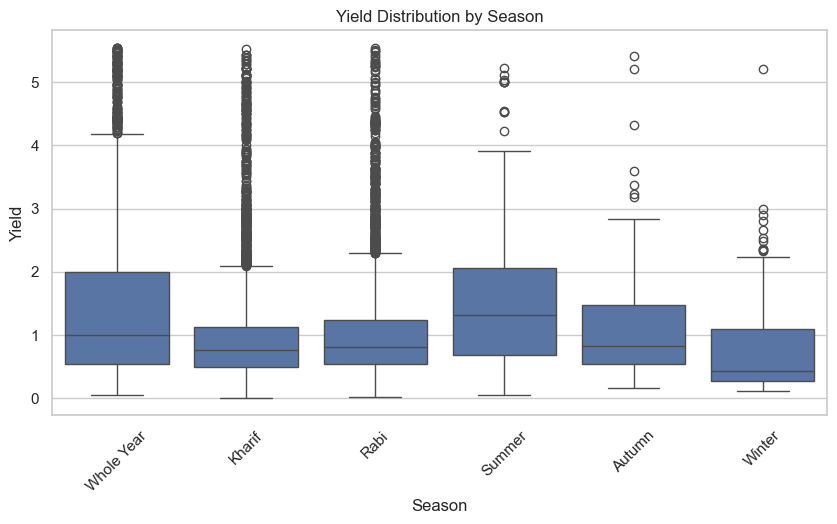

In [13]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Season", y="Yield")
plt.title("Yield Distribution by Season")
plt.xticks(rotation=45)
plt.show()

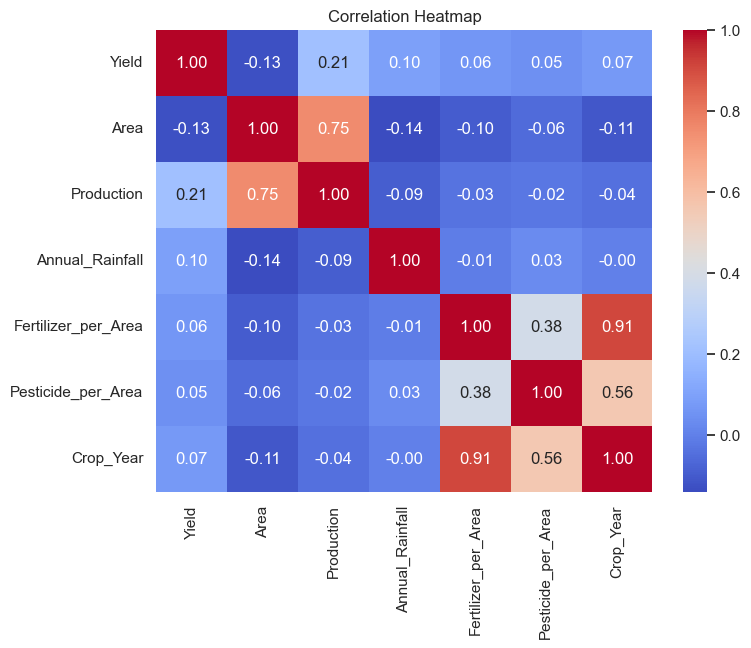

In [14]:
corr_cols = ["Yield", "Area", "Production", "Annual_Rainfall", "Fertilizer_per_Area", "Pesticide_per_Area", "Crop_Year"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

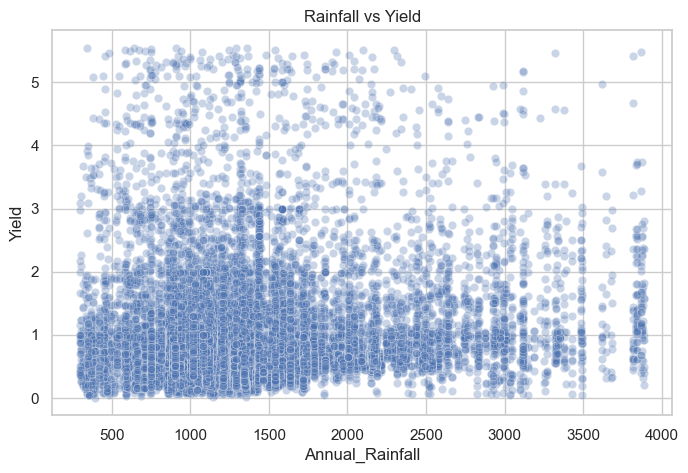

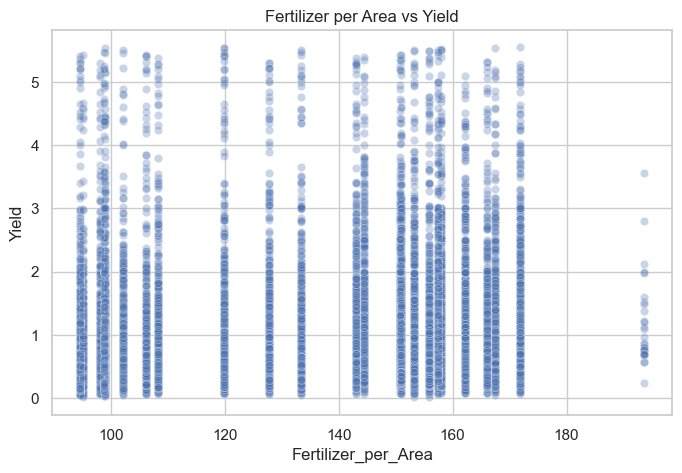

In [15]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Annual_Rainfall", y="Yield", alpha=0.3)
plt.title("Rainfall vs Yield")
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Fertilizer_per_Area", y="Yield", alpha=0.3)
plt.title("Fertilizer per Area vs Yield")
plt.show()

In [16]:
top_crops = df["Crop"].value_counts().head(10).index.tolist()
df_model = df[df["Crop"].isin(top_crops)].copy()
df_model.shape

(5288, 12)

In [17]:
df_model["Log_Yield"] = np.log1p(df_model["Yield"])

feature_cols_cat = ["Crop", "Season", "State"]
feature_cols_num = ["Crop_Year", "Area", "Annual_Rainfall", "Fertilizer_per_Area", "Pesticide_per_Area"]

X = df_model[feature_cols_cat + feature_cols_num]
y = df_model["Log_Yield"]
X.head()

,Crop,Season,State,Crop_Year,Area,Annual_Rainfall,Fertilizer_per_Area,Pesticide_per_Area
9,Maize,Kharif,Assam,1997,19216.0,2051.4,95.17,0.31
15,Rapeseed &Mustard,Rabi,Assam,1997,279292.0,2051.4,95.17,0.31
17,Rice,Summer,Assam,1997,174974.0,2051.4,95.17,0.31
19,Sesamum,Whole Year,Assam,1997,15765.0,2051.4,95.17,0.31
20,Small millets,Kharif,Assam,1997,10490.0,2051.4,95.17,0.31


In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((4230, 8), (1058, 8))

In [19]:
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), feature_cols_num),
    ("cat", "passthrough", []),
], remainder="drop")

from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), feature_cols_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), feature_cols_cat),
])

In [20]:
def evaluate_model(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_pred_orig = np.expm1(train_pred)
    test_pred_orig = np.expm1(test_pred)
    y_train_orig = np.expm1(y_train)
    y_test_orig = np.expm1(y_test)

    train_rmse = np.sqrt(mean_squared_error(y_train_orig, train_pred_orig))
    test_rmse = np.sqrt(mean_squared_error(y_test_orig, test_pred_orig))
    train_r2 = r2_score(y_train_orig, train_pred_orig)
    test_r2 = r2_score(y_test_orig, test_pred_orig)
    test_mae = mean_absolute_error(y_test_orig, test_pred_orig)

    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2")

    results = {
        "Model": name,
        "Train_RMSE": train_rmse,
        "Test_RMSE": test_rmse,
        "Train_R2": train_r2,
        "Test_R2": test_r2,
        "Test_MAE": test_mae,
        "CV_R2_Mean": cv_scores.mean(),
        "CV_R2_Std": cv_scores.std(),
    }
    return results, model

In [21]:
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression()),
])

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=-1)),
])

gb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=42)),
])

models = {
    "Linear Regression": lr_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline,
}

In [22]:
all_results = []
fitted_models = {}

for name, pipeline in models.items():
    result, fitted = evaluate_model(name, pipeline, X_train, X_test, y_train, y_test)
    all_results.append(result)
    fitted_models[name] = fitted

results_df = pd.DataFrame(all_results)
results_df

,Model,Train_RMSE,Test_RMSE,Train_R2,Test_R2,Test_MAE,CV_R2_Mean,CV_R2_Std
0,Linear Regression,0.422716,0.414328,0.692285,0.702917,0.280770,0.717129,0.019365
1,Random Forest,0.242518,0.297236,0.898717,0.847106,0.186567,0.838164,0.014048
2,Gradient Boosting,0.351170,0.359032,0.787633,0.776922,0.232975,0.790891,0.016768


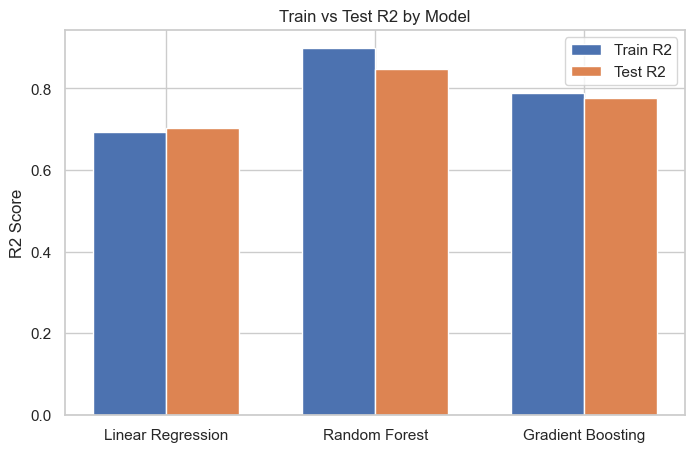

In [23]:
plt.figure(figsize=(8, 5))
x = np.arange(len(results_df))
width = 0.35
plt.bar(x - width/2, results_df["Train_R2"], width, label="Train R2")
plt.bar(x + width/2, results_df["Test_R2"], width, label="Test R2")
plt.xticks(x, results_df["Model"])
plt.ylabel("R2 Score")
plt.title("Train vs Test R2 by Model")
plt.legend()
plt.show()

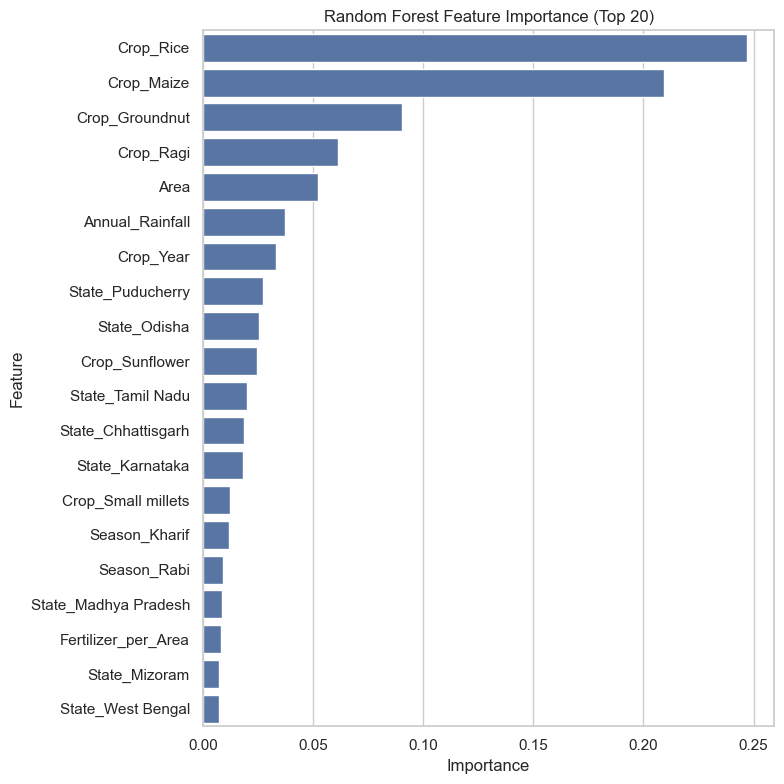

In [24]:
rf_model = fitted_models["Random Forest"].named_steps["model"]
ohe = fitted_models["Random Forest"].named_steps["preprocessor"].named_transformers_["cat"]
cat_feature_names = ohe.get_feature_names_out(feature_cols_cat).tolist()
all_feature_names = feature_cols_num + cat_feature_names

importances = rf_model.feature_importances_
importance_df = pd.DataFrame({"Feature": all_feature_names, "Importance": importances}).sort_values("Importance", ascending=False).head(20)

plt.figure(figsize=(8, 8))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance (Top 20)")
plt.tight_layout()
plt.show()

In [25]:
param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [8, 12, 16],
    "model__min_samples_leaf": [2, 3, 5],
}

grid_search = GridSearchCV(rf_pipeline, param_grid, cv=KFold(n_splits=5, shuffle=True, random_state=42),
                            scoring="r2", n_jobs=-1)
grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
grid_search.best_params_, grid_search.best_score_

({'model__max_depth': 16,
  'model__min_samples_leaf': 2,
  'model__n_estimators': 300},
 0.8641316059955036)

In [26]:
best_rf_result, best_rf = evaluate_model("Random Forest (Tuned)", best_rf, X_train, X_test, y_train, y_test)
results_df = pd.concat([results_df, pd.DataFrame([best_rf_result])], ignore_index=True)
fitted_models["Random Forest (Tuned)"] = best_rf
results_df

,Model,Train_RMSE,Test_RMSE,Train_R2,Test_R2,Test_MAE,CV_R2_Mean,CV_R2_Std
0,Linear Regression,0.422716,0.414328,0.692285,0.702917,0.280770,0.717129,0.019365
1,Random Forest,0.242518,0.297236,0.898717,0.847106,0.186567,0.838164,0.014048
2,Gradient Boosting,0.351170,0.359032,0.787633,0.776922,0.232975,0.790891,0.016768
3,Random Forest (Tuned),0.188342,0.279867,0.938914,0.864452,0.167049,0.864132,0.013206


In [27]:
best_model_name = results_df.sort_values("Test_R2", ascending=False).iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_model_name

'Random Forest (Tuned)'

In [28]:
sample_test = X_test.copy()
sample_test["Actual_Yield"] = np.expm1(y_test)
sample_test["Predicted_Yield"] = np.expm1(best_model.predict(X_test))
sample_test.head(15)

,Crop,Season,State,Crop_Year,Area,Annual_Rainfall,Fertilizer_per_Area,Pesticide_per_Area,Actual_Yield,Predicted_Yield
1981,Rice,Autumn,Meghalaya,2006,32679.0,2454.700000,127.71,0.22,1.641429,1.896289
5501,Moong(Green Gram),Rabi,Puducherry,2018,5.0,1693.900000,162.20,0.35,0.835000,0.807544
9897,Sesamum,Rabi,Maharashtra,2006,5000.0,1439.400000,127.71,0.22,0.643750,0.469678
17773,Groundnut,Kharif,Jammu and Kashmir,2006,39.0,1786.500000,127.71,0.22,0.500000,0.738037
19519,Moong(Green Gram),Autumn,Odisha,2013,24135.0,1632.400000,144.49,0.27,0.257500,0.276174
3514,Urad,Rabi,Karnataka,2011,8260.0,1178.986364,167.52,0.33,0.511250,0.434171
9824,Small millets,Kharif,Himachal Pradesh,2006,7479.0,1207.000000,127.71,0.22,0.548571,0.632486
16975,Rapeseed &Mustard,Rabi,Mizoram,2019,551.0,2178.500000,171.76,0.37,0.775000,0.805898
18247,Small millets,Rabi,Jammu and Kashmir,2016,74.0,902.800000,153.25,0.35,0.630000,0.827742
2646,Ragi,Summer,Karnataka,2008,8970.0,1164.100000,143.04,0.09,1.926000,1.899636


In [29]:
future_rows = []
last_year = int(df_model["Crop_Year"].max())
for crop in top_crops:
    crop_rows = df_model[df_model["Crop"] == crop]
    common_state = crop_rows["State"].mode().iloc[0]
    common_season = crop_rows["Season"].mode().iloc[0]
    recent = crop_rows[crop_rows["Crop_Year"] == crop_rows["Crop_Year"].max()]
    future_rows.append({
        "Crop": crop,
        "Season": common_season,
        "State": common_state,
        "Crop_Year": last_year + 1,
        "Area": recent["Area"].mean(),
        "Annual_Rainfall": recent["Annual_Rainfall"].mean(),
        "Fertilizer_per_Area": recent["Fertilizer_per_Area"].mean(),
        "Pesticide_per_Area": recent["Pesticide_per_Area"].mean(),
    })

future_df = pd.DataFrame(future_rows)
future_df = future_df[feature_cols_cat + feature_cols_num]
future_df

,Crop,Season,State,Crop_Year,Area,Annual_Rainfall,Fertilizer_per_Area,Pesticide_per_Area
0,Moong(Green Gram),Kharif,West Bengal,2021,8.5,1313.947826,193.61,0.37
1,Sesamum,Kharif,Odisha,2021,2017.0,1313.947826,193.61,0.37
2,Urad,Kharif,Odisha,2021,6228.0,1313.947826,193.61,0.37
3,Maize,Kharif,Odisha,2021,9947.5,1313.947826,193.61,0.37
4,Groundnut,Kharif,Odisha,2021,617.0,1313.947826,193.61,0.37
5,Rice,Kharif,Puducherry,2021,15315.0,1313.947826,193.61,0.37
6,Ragi,Kharif,Odisha,2021,85427.0,1313.947826,193.61,0.37
7,Small millets,Kharif,West Bengal,2021,44769.0,1313.947826,193.61,0.37
8,Sunflower,Kharif,Maharashtra,2021,3.0,1313.947826,193.61,0.37
9,Rapeseed &Mustard,Rabi,Mizoram,2021,13150.0,1313.947826,193.61,0.37


In [30]:
future_pred_log = best_model.predict(future_df)
future_df_result = future_df.copy()
future_df_result["Predicted_Yield"] = np.expm1(future_pred_log)
future_df_result

,Crop,Season,State,Crop_Year,Area,Annual_Rainfall,Fertilizer_per_Area,Pesticide_per_Area,Predicted_Yield
0,Moong(Green Gram),Kharif,West Bengal,2021,8.5,1313.947826,193.61,0.37,0.730192
1,Sesamum,Kharif,Odisha,2021,2017.0,1313.947826,193.61,0.37,0.340139
2,Urad,Kharif,Odisha,2021,6228.0,1313.947826,193.61,0.37,0.350204
3,Maize,Kharif,Odisha,2021,9947.5,1313.947826,193.61,0.37,2.024479
4,Groundnut,Kharif,Odisha,2021,617.0,1313.947826,193.61,0.37,1.109686
5,Rice,Kharif,Puducherry,2021,15315.0,1313.947826,193.61,0.37,3.183692
6,Ragi,Kharif,Odisha,2021,85427.0,1313.947826,193.61,0.37,0.662676
7,Small millets,Kharif,West Bengal,2021,44769.0,1313.947826,193.61,0.37,0.835580
8,Sunflower,Kharif,Maharashtra,2021,3.0,1313.947826,193.61,0.37,0.729617
9,Rapeseed &Mustard,Rabi,Mizoram,2021,13150.0,1313.947826,193.61,0.37,0.779460
